In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import uncertainties as unc
from uncertainties import ufloat
import uncertainties.unumpy as unp
from scipy import constants

# 1. Dynamische Pfadfindung zu 'common'
current_dir = Path.cwd()
if (current_dir / "common").exists():
    common_dir = (current_dir / "common").resolve()
elif (current_dir / "../common").exists():
    common_dir = (current_dir / "../common").resolve()
else:
    raise FileNotFoundError("Der Ordner 'common' konnte nicht gefunden werden.")

sys.path.insert(0, str(common_dir))

# Eigene Module importieren
import io_utils
from common.io_utils import load_messdaten
import fitting
from common.plotting import plot_with_fit
import fit_stats as stats
import fitting
from common.fitting import perform_fit
import plotting
import uncertainty

print("Module erfolgreich geladen.")

# Messwerte direkt aus den .txt Dateien importiert.

angle, intensity = load_messdaten('data/raw/V255_X_Ray_Spektrum.txt').T

Module erfolgreich geladen.


Plot gespeichert unter: figures\V255_einfacher_Plot.pdf


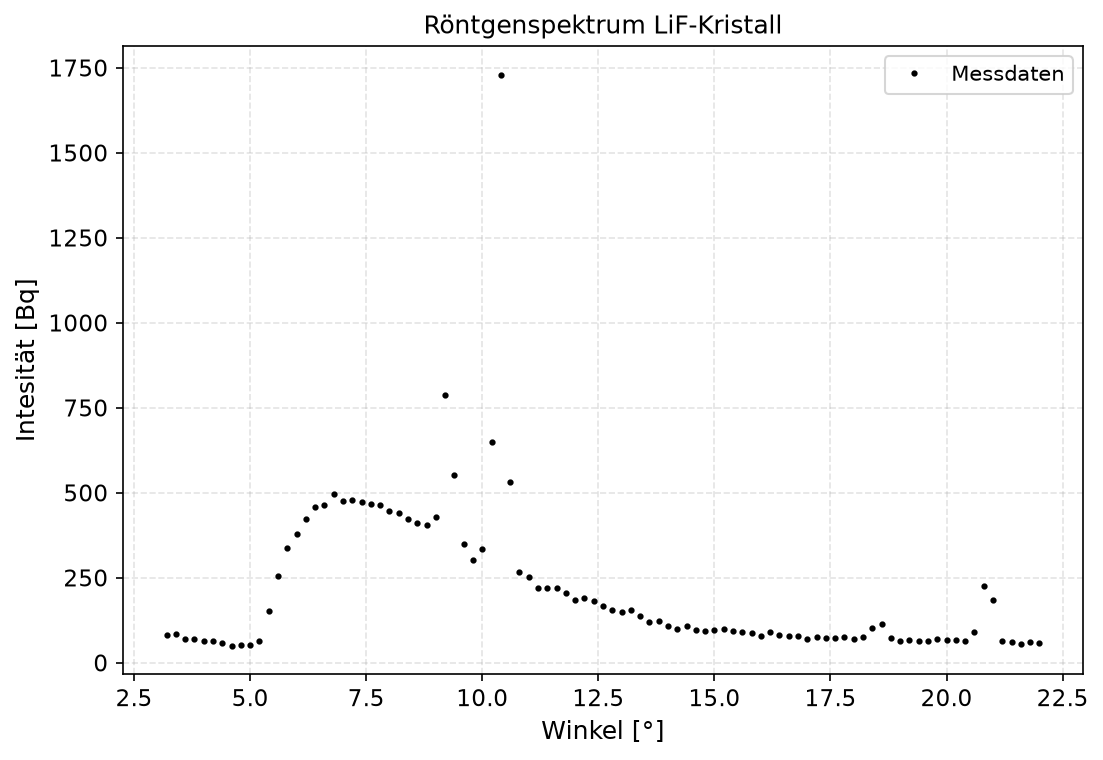

WindowsPath('figures/V255_einfacher_Plot.pdf')

In [3]:
## Plot des geamten Spektrums; "annähernd" geraden Anstieg am kurzwelligen Ende identifizieren
import matplotlib.pyplot as plt


plot_with_fit(
    x=angle, y=intensity, xlabel="Winkel [°]", ylabel="Intesität [Bq]", title="Röntgenspektrum LiF-Kristall", filename= 'V255_einfacher_Plot') # Plot hier noch ohne fit ;)
# wir sehen, dass wir ca vom 11.-17. Datenpunkt ausgehend eine ungefähr lineare Funktion zur
# Extrapolation fitten können
# den Mittelwert des Untergrunds können wir einigermaßen sinnvoll aus den Datenpunkten 5 bis 11 ermitteln

<function matplotlib.pyplot.show(close=None, block=None)>

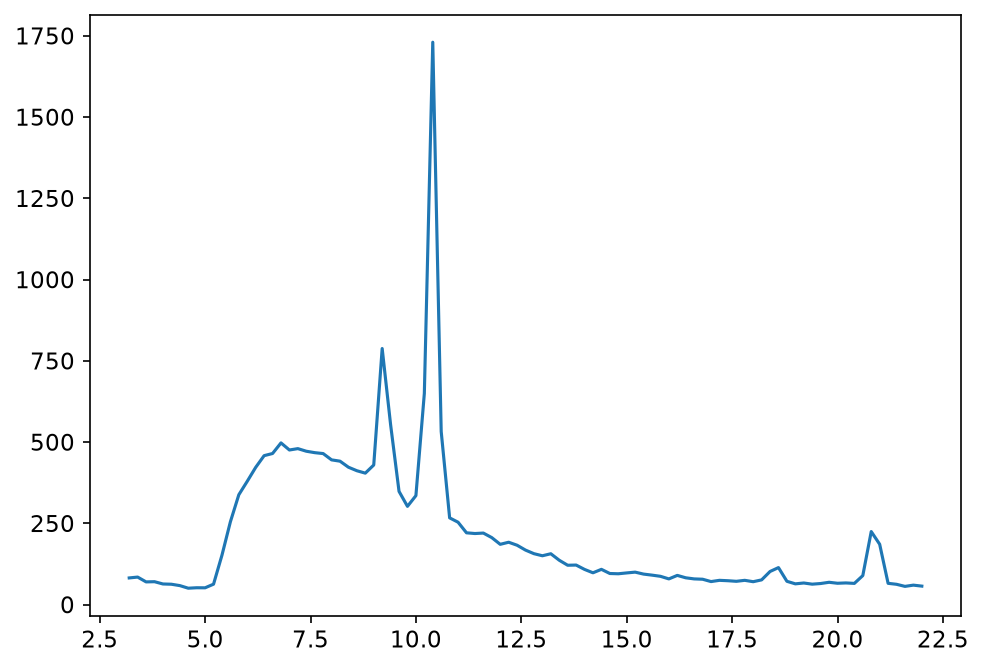

In [4]:
plt.plot(angle, intensity)
plt.show

Plot gespeichert unter: figures\V255_Extrapolation.pdf


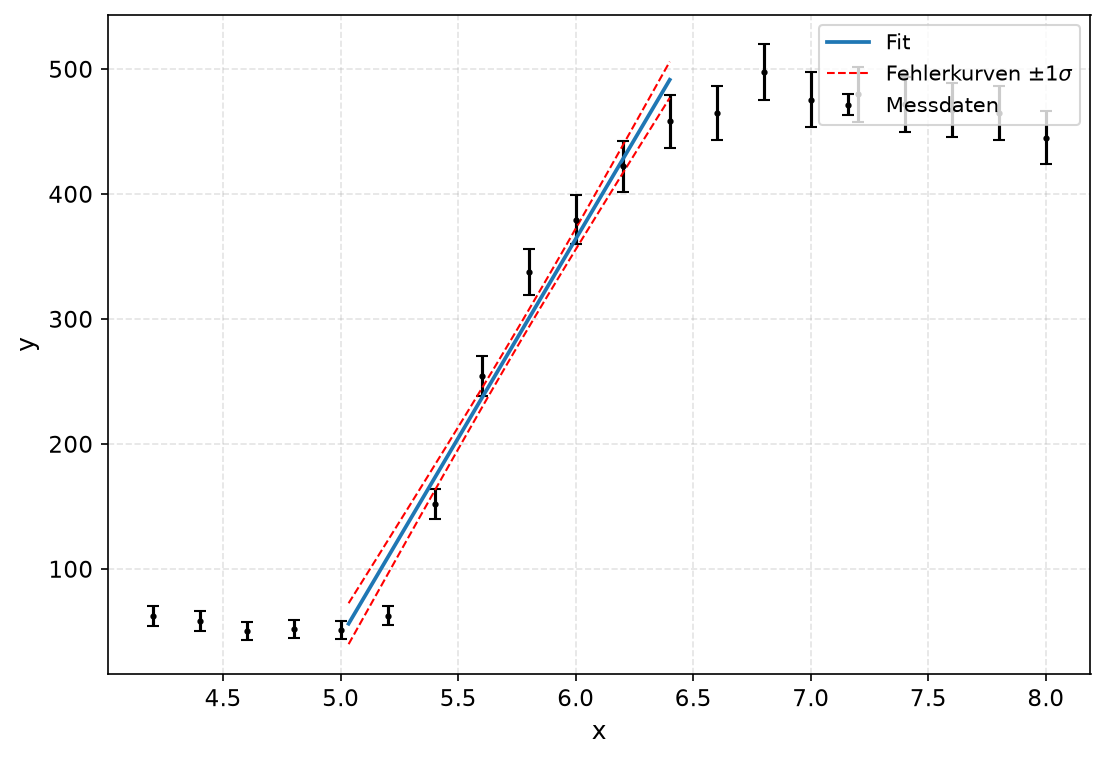

Nullstelle x_0:  5.03387170576518 pm 0.05185081825074778
Grenzwellenlänge lambda_gr:  3.538905553452229e-11 pm 3.6452090832680653e-13
Planck'sches Wirkungsquantum:  6.619523182554177e-34 pm 6.81836394543264e-36


In [8]:
## jetzt der Plot mit fit für den einigermaßen geraden anstieg
hintergrund = intensity[5:11]
#Mittelwert der Hintergrundwerte mit Fehler
y_hintergrund = unc.ufloat(np.mean(hintergrund), np.std(hintergrund) / np.sqrt(len(hintergrund)))
Delta_intensity=np.sqrt(intensity)
popt_b, perr_b, pcov_b = fitting.perform_fit(fitting.linear, angle[11:17],intensity[11:17], Delta_intensity[11:17],)
# extrapolierte Nullstelle
fit_paramter_fehler = unc.correlated_values(popt_b, pcov_b) # [0] ist für m und [1] für c
x_0 = (y_hintergrund - fit_paramter_fehler[1]) /fit_paramter_fehler[0]
x_fit = np.linspace(x_0.n, angle[11:17].max(), 100)
# y-Paramter mit Fehlern in np array (mit Fehlern aus Covarianzmatrix)
# berechnet 1-sigma Fehler

y_fit_unc = fitting.linear(x_fit,fit_paramter_fehler[0], fit_paramter_fehler[1])
# nur die nominalen Werte
y_fit = np.array([val.n for val in y_fit_unc])
# nur die Fehlerwerte
y_fit_err = np.array([val.s for val in y_fit_unc])
# Grenzwellenlänge
lambda_0 = 2*201.4e-12 * unp.radians(x_0)/1
# h
h = (lambda_0 * constants.e * 35e3)/constants.c

plot_with_fit(x = angle[5:25], y = intensity[5:25], connect_points= True, y_err= Delta_intensity[5:25], x_fit =x_fit, y_fit= y_fit,
              y_fit_lower= y_fit - y_fit_err, y_fit_upper= y_fit + y_fit_err, filename= 'V255_Extrapolation' )
print("Nullstelle x_0: ", x_0.n, "pm", x_0.s)
print("Grenzwellenlänge lambda_gr: ", lambda_0.n, "pm", lambda_0.s)
print("Planck'sches Wirkungsquantum: ", h.n, "pm", h.s )

In [13]:
## Berechnung Winkel Spektrum zweiter Ordnung

theta_2 = lambda_0*1/201.4e-12

print("theta_2: ", unp.degrees(theta_2.n), "pm", unp.degrees(theta_2.s))

theta_2:  10.067743411530362 pm 0.10370163650149554
